# Romper una molécula, un qubit a la vez — H₄ con VQE

**Quantum Jam 2026 · equipo quantum-toffolis** (Octavio, Gonzalo, Santino, Joaquín)

Calculamos con **VQE** la curva de energía de la cadena lineal H₄ (STO-3G, 8 qubits con Jordan-Wigner) entre 0,6 y 3,0 Å y la comparamos con CCSD y FCI.

**Resumen de la estrategia**
1. Hamiltoniano por punto con PySCF → Jordan-Wigner (185 cadenas de Pauli).
2. Ansatz químico que conserva N_α, N_β (UCCSD, 2 pasos de Trotter) desde Hartree-Fock.
3. Parámetros buscados sin ruido con gradiente analítico (permitido por la consigna).
4. **Energía reportada = medición con `SamplerV2` de `qiskit_aer`**: grupos QWC, rotación de base, shots repartidos en dos etapas (piloto + Neyman) y σ calculada desde las muestras.
5. R_e por ajuste cuadrático con incertidumbre Monte Carlo; D_e = E(3,0 Å) − E(R_e).


## 0 · Instalación y código

El notebook instala sus dependencias y escribe el paquete `h4vqe/` con `%%writefile`, así corre de punta a punta en un Colab nuevo.
Cada módulo tiene un dueño en el equipo; acá solo se copian.


In [1]:
# Instala dependencias si faltan (Colab arranca sin Qiskit ni PySCF).
import importlib.util, os, subprocess, sys
REQS = {"qiskit": "qiskit==2.6.2", "qiskit_aer": "qiskit-aer==0.18.4", "pyscf": "pyscf==2.15.0"}
missing = [pip for mod, pip in REQS.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
os.makedirs("h4vqe", exist_ok=True)
print("python", sys.version.split()[0], "- instalado:", missing or "nada (ya estaba)")

python 3.13.7 - instalado: nada (ya estaba)


In [2]:
%%writefile h4vqe/__init__.py
"""VQE para la curva de disociación de H4 lineal (Quantum Jam 2026)."""


Writing h4vqe/__init__.py


In [3]:
%%writefile h4vqe/config.py
"""Configuración compartida. Cambiar acá, no en los módulos.

Dueño: todos (avisar en el grupo antes de tocar).
"""

BASIS = "sto-3g"

# Distancias H-H (Å). La consigna pide >= 10 puntos entre 0,6 y 3,0 Å.
# Hay puntos densos cerca del mínimo (~0,9 Å) para ajustar R_e.
DISTANCES = [0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 1.0, 1.1, 1.2, 1.4, 1.6,
             1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0]

STRETCHED_FROM = 1.8          # zona donde hay que ganarle a CCSD
CHEM_ACC = 1.6e-3             # Ha

# Presupuesto de shots por punto de la curva (estimación final, no optimización).
SHOTS_PER_POINT = 8_000_000   # σ ≈ 0,7 mHa con QWC + Neyman (medido a 2,0 Å)

# Compuertas nativas del modelo de ruido de la consigna (ruido.py).
BASIS_GATES = ["cz", "rz", "sx", "x"]

SEED = 1234

# UCCSD con 2 pasos de Trotter: llega a FCI (<1 µHa) en toda la curva sin ruido.
# Con 1 paso el error máximo es ~4,5 mHa (a 2,0 Å): le gana a CCSD pero sin precisión química.
ANSATZ_REPS = 2


Writing h4vqe/config.py


In [4]:
%%writefile h4vqe/hamiltonian.py
"""Molécula H4 lineal -> hamiltoniano de qubits + referencias clásicas.

Dueño: Octavio.

Convención de qubits (Jordan-Wigner, little-endian de Qiskit):
    qubits 0..norb-1      -> espín-orbitales alfa (orbital 0 = el de menor energía)
    qubits norb..2norb-1  -> espín-orbitales beta
El estado HF ocupa los qubits 0,1 (alfa) y 4,5 (beta): bitstring '00110011'.
"""
from __future__ import annotations

import numpy as np
from pyscf import gto, scf, mcscf, ao2mo, cc
from qiskit.quantum_info import SparsePauliOp

from .config import BASIS


def h4_geometry(d: float) -> str:
    """Cadena recta de 4 H separados por d Å."""
    return "; ".join(f"H 0 0 {i * d:.6f}" for i in range(4))


def molecule(d: float, basis: str = BASIS) -> dict:
    """Integrales en base de orbitales HF + energías HF, FCI y CCSD."""
    mol = gto.M(atom=h4_geometry(d), basis=basis, unit="Angstrom", verbose=0)
    hf = scf.RHF(mol)
    hf.conv_tol = 1e-10
    hf.kernel()
    norb = mol.nao_nr()
    nelec = mol.nelectron
    cas = mcscf.CASCI(hf, norb, nelec)
    h1, ecore = cas.get_h1cas()
    g = ao2mo.restore(1, cas.get_h2cas(), norb)
    e_fci = cas.kernel()[0]

    ccsd = cc.CCSD(hf)
    ccsd.conv_tol = 1e-9
    ccsd.max_cycle = 500
    ccsd.kernel()

    return {
        "d": d, "mol": mol, "hf": hf, "norb": norb,
        "nelec": (nelec // 2, nelec // 2),
        "h": h1, "g": g, "constante": ecore,
        "e_hf": hf.e_tot, "e_fci": e_fci,
        "e_ccsd": ccsd.e_tot, "ccsd_converged": bool(ccsd.converged),
    }


def _annihilation_jw(p: int, n_qubits: int) -> SparsePauliOp:
    return SparsePauliOp.from_sparse_list(
        [("Z" * p + "X", list(range(p + 1)), 0.5),
         ("Z" * p + "Y", list(range(p + 1)), 0.5j)], n_qubits)


def annihilation_ops(n_qubits: int) -> list[SparsePauliOp]:
    return [_annihilation_jw(p, n_qubits) for p in range(n_qubits)]


def qubit_hamiltonian(m: dict) -> SparsePauliOp:
    """Ĥ = E_core + Σ h_pq a†_p a_q + ½ Σ g_pqrs a†_p a†_r a_s a_q  (Jordan-Wigner)."""
    norb = m["norb"]
    nq = 2 * norb
    h, g = m["h"], m["g"]
    a = annihilation_ops(nq)
    ad = [op.adjoint() for op in a]
    hop = [[[ad[s * norb + p].dot(a[s * norb + q]).simplify() for q in range(norb)]
            for p in range(norb)] for s in range(2)]
    terms = [SparsePauliOp("I" * nq, m["constante"])]
    for s in range(2):
        for p in range(norb):
            for q in range(norb):
                terms.append(h[p, q] * hop[s][p][q])
    for s in range(2):
        for t in range(2):
            for p in range(norb):
                for q in range(norb):
                    second = SparsePauliOp.sum([g[p, q, r, u] * hop[t][r][u]
                                                for r in range(norb) for u in range(norb)])
                    terms.append(0.5 * hop[s][p][q].dot(second))
                    if s == t:
                        for u in range(norb):
                            terms.append(-0.5 * g[p, q, q, u] * hop[s][p][u])
    return SparsePauliOp.sum(terms).simplify(atol=1e-10).chop(1e-10)


def number_operators(norb: int) -> dict[str, SparsePauliOp]:
    """N_alfa, N_beta y S^2 en qubits, para chequear simetrías del estado."""
    nq = 2 * norb
    a = annihilation_ops(nq)
    n = [a[p].adjoint().dot(a[p]).simplify() for p in range(nq)]
    na = SparsePauliOp.sum(n[:norb]).simplify()
    nb = SparsePauliOp.sum(n[norb:]).simplify()
    sz = 0.5 * (na - nb)
    sp = SparsePauliOp.sum([a[p].adjoint().dot(a[norb + p]) for p in range(norb)]).simplify()
    s2 = (sp.dot(sp.adjoint()) + sz.dot(sz) - sz).simplify(atol=1e-12)
    return {"N_alpha": na, "N_beta": nb, "S2": s2}


def exact_ground_energy(H: SparsePauliOp) -> float:
    """Diagonalización completa (256x256). Solo como chequeo contra FCI."""
    return float(np.linalg.eigvalsh(H.to_matrix())[0])


Writing h4vqe/hamiltonian.py


In [5]:
%%writefile h4vqe/ansatz.py
"""Ansatz que conserva el número de partículas (UCCSD con Trotter, 1 paso por defecto).

Dueño: Gonzalo.

Cada excitación k es una compuerta exp(-i θ_k G_k) con G_k = i(T_k - T_k†).
Los términos de Pauli de un mismo G_k conmutan entre sí, así que el circuito
implementa EXACTAMENTE Π_k exp(-i θ_k G_k). Eso permite optimizar con un
simulador numpy rápido (`FastAnsatz`) y después medir el MISMO circuito con shots.

Interfaz que usan los otros módulos (no romperla):
    build_ansatz(m, ...) -> Ansatz   con .circuit (parametrizado), .fast, .excitations
    cz_count(circuit, coupling="all"|"line") -> int
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import CouplingMap

from .config import BASIS_GATES, SEED
from .hamiltonian import annihilation_ops


def hf_occupation(m: dict) -> list[int]:
    norb = m["norb"]
    na, nb = m["nelec"]
    return list(range(na)) + [norb + i for i in range(nb)]


def uccsd_excitations(m: dict) -> list[tuple[tuple[int, ...], tuple[int, ...]]]:
    """Simples y dobles ocupado -> vacío que conservan S_z."""
    norb = m["norb"]
    na, nb = m["nelec"]
    occ = [list(range(na)), [norb + i for i in range(nb)]]
    vac = [list(range(na, norb)), [norb + i for i in range(nb, norb)]]
    ex = [((i,), (a,)) for s in range(2) for i in occ[s] for a in vac[s]]
    ex += [((i, j), (a, b)) for i in occ[0] for j in occ[1] for a in vac[0] for b in vac[1]]
    for s in range(2):
        for x, i in enumerate(occ[s]):
            for j in occ[s][x + 1:]:
                for y, a in enumerate(vac[s]):
                    for b in vac[s][y + 1:]:
                        ex.append(((i, j), (a, b)))
    return ex


def excitation_generator(exc, nq: int, a=None) -> SparsePauliOp:
    """G = i(T - T†), con T = a†_a a†_b a_j a_i."""
    a = a or annihilation_ops(nq)
    src, dst = exc
    T = SparsePauliOp("I" * nq)
    for p in dst:
        T = T.dot(a[p].adjoint())
    for p in reversed(src):
        T = T.dot(a[p])
    return (1j * (T - T.adjoint())).simplify(atol=1e-12)


class FastAnsatz:
    """Simulador numpy exacto de Π_k exp(-i θ_k G_k)|HF> (solo para OPTIMIZAR)."""

    def __init__(self, generators: list[SparsePauliOp], hf_index: int, nq: int):
        self.G = [g.to_matrix(sparse=False) for g in generators]
        self.G2 = [G @ G for G in self.G]
        for G, G2 in zip(self.G, self.G2):  # exp cerrada requiere G^3 = G
            assert np.allclose(G2 @ G, G, atol=1e-10), "G^3 != G"
        self.psi0 = np.zeros(2 ** nq, dtype=complex)
        self.psi0[hf_index] = 1.0

    def state(self, theta) -> np.ndarray:
        psi = self.psi0
        for t, G, G2 in zip(theta, self.G, self.G2):
            # exp(-i t G) = I + (cos t - 1) G^2 - i sin t G
            psi = psi + (np.cos(t) - 1.0) * (G2 @ psi) - 1j * np.sin(t) * (G @ psi)
        return psi

    def energy_and_grad(self, theta, Hm: np.ndarray):
        """Energía y gradiente analítico (barrido hacia atrás)."""
        n = len(theta)
        states = [self.psi0]
        for t, G, G2 in zip(theta, self.G, self.G2):
            p = states[-1]
            states.append(p + (np.cos(t) - 1.0) * (G2 @ p) - 1j * np.sin(t) * (G @ p))
        psi = states[-1]
        lam = Hm @ psi
        e = float(np.real(np.vdot(psi, lam)))
        grad = np.zeros(n)
        for k in reversed(range(n)):
            # dE/dθ_k = 2 Re <λ| (-i G_k) |ψ_k>, con ψ_k el estado después de la compuerta k
            grad[k] = 2.0 * np.real(np.vdot(lam, -1j * (self.G[k] @ states[k + 1])))
            t, G, G2 = theta[k], self.G[k], self.G2[k]
            # λ <- U_k† λ
            lam = lam + (np.cos(t) - 1.0) * (G2 @ lam) + 1j * np.sin(t) * (G @ lam)
        return e, grad


@dataclass
class Ansatz:
    circuit: QuantumCircuit          # parametrizado, en compuertas nativas (sin acoplamiento)
    excitations: list
    fast: FastAnsatz
    params: ParameterVector
    meta: dict = field(default_factory=dict)

    @property
    def num_parameters(self) -> int:
        return len(self.params)


def build_ansatz(m: dict, excitations=None, reps: int = 1) -> Ansatz:
    """UCCSD (o la lista de excitaciones que se pase, p. ej. la de ADAPT)."""
    norb = m["norb"]
    nq = 2 * norb
    excitations = list(excitations or uccsd_excitations(m)) * reps
    a = annihilation_ops(nq)
    gens = [excitation_generator(e, nq, a) for e in excitations]
    theta = ParameterVector("θ", len(gens))
    qc = QuantumCircuit(nq)
    occ = hf_occupation(m)
    for q in occ:
        qc.x(q)
    for t, G in zip(theta, gens):
        qc.append(PauliEvolutionGate(G, time=t), range(nq))
    native = transpile(qc, basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=SEED)
    hf_index = sum(1 << q for q in occ)
    return Ansatz(native, excitations, FastAnsatz(gens, hf_index, nq), theta,
                  {"reps": reps, "n_qubits": nq})


def cz_count(circuit: QuantumCircuit, coupling: str = "all", seed: int = SEED) -> int:
    """CZ después de transpilar. coupling='line' = qubits en línea (modelo de ruido)."""
    kw = {}
    if coupling == "line":
        kw["coupling_map"] = CouplingMap.from_line(circuit.num_qubits)
    t = transpile(circuit, basis_gates=BASIS_GATES, optimization_level=3,
                  seed_transpiler=seed, **kw)
    return int(t.count_ops().get("cz", 0))


Writing h4vqe/ansatz.py


In [6]:
%%writefile h4vqe/optimize.py
"""Búsqueda de parámetros SIN ruido (permitido por la consigna).

Dueño: Gonzalo.

Los θ* se buscan con el simulador numpy exacto del ansatz. La energía que se
REPORTA no sale de acá: sale de medir el circuito con shots (estimator.py).
"""
from __future__ import annotations

import numpy as np
from scipy.optimize import minimize

from .ansatz import Ansatz


def optimize_params(ans: Ansatz, H, x0=None, tol: float = 1e-10, maxiter: int = 2000,
                    n_restarts: int = 0, seed: int = 0) -> dict:
    """L-BFGS-B con gradiente analítico. Devuelve dict con x, energy, nfev."""
    Hm = H.to_matrix(sparse=True)
    fun = lambda x: ans.fast.energy_and_grad(x, Hm)
    starts = [np.zeros(ans.num_parameters) if x0 is None else np.asarray(x0, float)]
    rng = np.random.default_rng(seed)
    starts += [starts[0] + rng.normal(0, 0.1, ans.num_parameters) for _ in range(n_restarts)]
    best = None
    for s in starts:
        r = minimize(fun, s, jac=True, method="L-BFGS-B",
                     options={"maxiter": maxiter, "ftol": tol, "gtol": 1e-8})
        if best is None or r.fun < best.fun:
            best = r
    return {"x": best.x, "energy": float(best.fun), "nfev": int(best.nfev),
            "success": bool(best.success)}


def exact_state(ans: Ansatz, x) -> np.ndarray:
    """Solo para diagnóstico (fidelidad, varianza). NUNCA para la energía reportada."""
    return ans.fast.state(x)


Writing h4vqe/optimize.py


In [7]:
%%writefile h4vqe/estimator.py
"""Energía MEDIDA con SamplerV2 de qiskit_aer, con barra de error ±σ.

Dueño: Santino.

Método:
  1. Se agrupan los términos de Pauli que conmutan qubit a qubit (QWC).
  2. Cada grupo se mide en su base (H para X, S†H para Y) con N_g shots.
  3. Cada shot da UNA muestra del observable del grupo O_g = Σ c_k P_k,
     así que E_g = media muestral y σ_g² = var muestral / N_g
     (las covarianzas dentro del grupo quedan incluidas).
  4. E = constante + Σ_g E_g ;  σ² = Σ_g σ_g²  (grupos independientes).

Interfaz: measure_energy(circuit_bound, H, total_shots, ...) -> dict

Asignación de shots en dos etapas (piloto + Neyman), ver measure_energy.

Implementación: para cada grupo se precalcula una tabla con el valor de O_g para
cada bitstring posible (2^n entradas). Los conteos se hacen con np.bincount
sobre el arreglo de bits del SamplerV2 (mucho más rápido que get_counts con
millones de shots). Los circuitos de medición se transpilan una sola vez
(`prepare_measurement`) y se pueden reusar entre llamadas.
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Pauli, SparsePauliOp, StabilizerState
from qiskit_aer.primitives import SamplerV2 as AerSampler

from .config import BASIS_GATES, SEED


def split_constant(H: SparsePauliOp) -> tuple[float, SparsePauliOp]:
    ident = "I" * H.num_qubits
    const = sum(c for p, c in H.to_list() if p == ident)
    rest = SparsePauliOp.from_list([(p, c) for p, c in H.to_list() if p != ident])
    return float(np.real(const)), rest


def measurement_groups(H: SparsePauliOp, method: str = "sorted",
                       grouping: str = "qwc") -> list[SparsePauliOp]:
    """Grupos de términos que se miden juntos.
    grouping="qwc": conmutan qubit a qubit (se miden con H / S†H por qubit).
    grouping="gc":  conmutan en general (se miden con un Clifford, ver diagonalize_group).
    method="sorted": sorted insertion (Crawford et al., Quantum 5, 385 (2021)): se recorren
        los términos por |c| decreciente y cada uno va al primer grupo compatible. Pone los
        términos grandes juntos y sus covarianzas se compensan: para H4 baja la σ²·N
        de Neyman ~1,9× (QWC) contra el coloreo (scripts/shots_study.py).
    method="coloring": group_commuting de qiskit (lo que se usaba antes)."""
    _, rest = split_constant(H)
    if method == "coloring":
        return rest.group_commuting(qubit_wise=(grouping == "qwc"))
    labels = [p.to_label() for p in rest.paulis]
    groups: list[tuple[list[str], list[int]]] = []  # (base común por qubit, índices)
    for k in np.argsort(-np.abs(rest.coeffs), kind="stable"):
        lab = labels[k]
        for basis, idx in groups:
            if grouping == "qwc":
                ok = all(a == "I" or b == "I" or a == b for a, b in zip(lab, basis))
            else:
                ok = all(rest.paulis[k].commutes(rest.paulis[j]) for j in idx)
            if ok:
                for q, a in enumerate(lab):
                    if a != "I":
                        basis[q] = a
                idx.append(k)
                break
        else:
            groups.append((list(lab), [k]))
    return [rest[idx] for _, idx in groups]


def _independent_generators(paulis) -> list:
    """Subconjunto independiente (en GF(2), vectores simplécticos [x|z]) que genera el grupo."""
    rows, gens = [], []
    for p in paulis:
        v = np.concatenate([p.x, p.z]).astype(np.uint8)
        for r, piv in rows:  # reducir contra los ya elegidos
            if v[piv]:
                v ^= r
        if v.any():
            piv = int(np.flatnonzero(v)[0])
            rows = [(r ^ v if r[piv] else r, pv) for r, pv in rows]
            rows.append((v, piv))
            gens.append(p)
    return gens


def diagonalize_group(group: SparsePauliOp) -> tuple[QuantumCircuit, SparsePauliOp]:
    """Clifford U tal que U P U† es un string de Z (con signo) para todo P del grupo.
    Se completa un conjunto independiente de generadores a un estado estabilizador
    C|0>; entonces C† P C = ±Z... y medir O_g en |ψ> = medir Σ c ±Z en C†|ψ>.
    Devuelve (circuito C†, O_g reescrito en Z con los signos en los coeficientes)."""
    gens = _independent_generators(group.paulis)
    C = StabilizerState.from_stabilizer_list([g.to_label() for g in gens],
                                             allow_underconstrained=True).clifford
    labels, coeffs = [], []
    for p, c in zip(group.paulis, group.coeffs):
        q = p.evolve(C, frame="h")  # C† P C
        assert not q.x.any() and q.phase in (0, 2), (p, q)
        labels.append(Pauli((q.z, np.zeros_like(q.x))).to_label())
        coeffs.append(c * (-1 if q.phase == 2 else 1))
    return C.adjoint().to_circuit(), SparsePauliOp(labels, coeffs)


def group_basis(group: SparsePauliOp) -> str:
    """Base común del grupo: por qubit X, Y, Z o I (string little-endian como Pauli)."""
    nq = group.num_qubits
    basis = ["I"] * nq
    for p in group.paulis:
        lab = p.to_label()  # lab[-1-q] es el qubit q
        for q in range(nq):
            ch = lab[-1 - q]
            if ch != "I":
                basis[q] = ch
    return "".join(reversed(basis))


def rotate_and_measure(circ: QuantumCircuit, basis: str) -> QuantumCircuit:
    qc = circ.copy()
    nq = qc.num_qubits
    for q in range(nq):
        ch = basis[-1 - q]
        if ch == "X":
            qc.h(q)
        elif ch == "Y":
            qc.sdg(q)
            qc.h(q)
    qc.measure_all()
    return qc


def value_table(group: SparsePauliOp) -> np.ndarray:
    """table[x] = valor de O_g = Σ c_k P_k cuando se mide el bitstring x (bit q = qubit q),
    ya rotado a la base del grupo (cada P_k actúa como Z en su soporte)."""
    nq = group.num_qubits
    xs = np.arange(2 ** nq, dtype=np.uint64)
    table = np.zeros(2 ** nq)
    for p, c in zip(group.paulis, np.real(group.coeffs)):
        mask = np.uint64(int(np.dot(p.z | p.x, 1 << np.arange(nq, dtype=np.int64))))
        parity = np.bitwise_count(xs & mask) & 1
        table += c * (1 - 2 * parity.astype(float))
    return table


def group_outcome_values(group: SparsePauliOp) -> np.ndarray:
    """Alias de value_table (nombre que usa h4vqe/noise.py)."""
    return value_table(group)


@dataclass
class MeasurementPlan:
    """Lo que no depende de los shots: grupos, circuitos transpilados y tablas de valores."""
    const: float
    groups: list
    circuits: list
    tables: list
    num_qubits: int

    @property
    def n_groups(self) -> int:
        return len(self.groups)


def prepare_measurement(circuit: QuantumCircuit, H: SparsePauliOp,
                        grouping: str = "qwc") -> MeasurementPlan:
    """grouping="qwc": rotaciones de 1 qubit (sin CZ extra).
    grouping="gc": un Clifford por grupo (menos shots, pero agrega CZ al circuito medido)."""
    const, _ = split_constant(H)
    groups = measurement_groups(H, grouping=grouping)
    if grouping == "qwc":
        circs = [rotate_and_measure(circuit, group_basis(g)) for g in groups]
        tables = [value_table(g) for g in groups]
    else:
        circs, tables = [], []
        for g in groups:
            diag, gz = diagonalize_group(g)
            qc = circuit.compose(diag)
            qc.measure_all()
            circs.append(qc)
            tables.append(value_table(gz))
    circs = transpile(circs, basis_gates=BASIS_GATES + ["measure"], optimization_level=1,
                      seed_transpiler=SEED)
    return MeasurementPlan(const, groups, circs, tables, circuit.num_qubits)


def allocate_shots(groups, total_shots: int, weights=None) -> list[int]:
    """Por defecto: N_g ∝ Σ|c_k| (proxy de la desviación del grupo).
    Con weights = σ_g estimadas -> asignación de Neyman (N_g ∝ σ_g)."""
    if weights is None:
        weights = np.array([np.sum(np.abs(g.coeffs)) for g in groups])
    w = np.asarray(weights, float)
    w = w / w.sum()
    shots = np.maximum(100, np.floor(w * total_shots)).astype(int)
    return shots.tolist()


def _bitarray_to_int(bitarray) -> np.ndarray:
    """BitArray del SamplerV2 -> entero por shot (bit q = qubit q)."""
    arr = bitarray.array  # (shots, nbytes) uint8, big-endian
    x = np.zeros(arr.shape[0], dtype=np.int64)
    for i in range(arr.shape[1]):
        x = (x << 8) | arr[:, i]
    return x


def _outcome_hist(bitarray, nq: int) -> np.ndarray:
    """Histograma de resultados (2^nq entradas) de un BitArray del SamplerV2. Lo usa noise.py."""
    return np.bincount(_bitarray_to_int(bitarray), minlength=2 ** nq)


def _sample_counts(plan: MeasurementPlan, shots, seed) -> np.ndarray:
    """Corre un circuito por grupo; devuelve conteos por bitstring, shape (n_groups, 2^n)."""
    # Una semilla INDEPENDIENTE por grupo. Con una sola corrida y seed fija, Aer usa
    # semillas consecutivas por circuito y vimos errores correlacionados entre grupos
    # (σ subestimada, desvíos de 4σ). SeedSequence da flujos independientes.
    ss = seed if isinstance(seed, np.random.SeedSequence) else np.random.SeedSequence(seed)
    seeds = ss.generate_state(plan.n_groups)
    counts = np.zeros((plan.n_groups, 2 ** plan.num_qubits))
    for i, (c, n, sd) in enumerate(zip(plan.circuits, shots, seeds)):
        r = AerSampler(seed=int(sd)).run([(c, None, int(n))]).result()[0]
        counts[i] = _outcome_hist(r.data.meas, plan.num_qubits)
    return counts


def _combine(const, hists, values):
    """E = const + Σ_g media_g ; σ² = Σ_g var_g / N_g, a partir de los histogramas
    hists (G, 2^n) y las tablas de valores values (G, 2^n). Firma usada también por noise.py."""
    hists, values = np.asarray(hists, float), np.asarray(values, float)
    n = hists.sum(axis=1)
    mean = np.einsum("gx,gx->g", hists, values) / n
    svar = np.einsum("gx,gx->g", hists, (values - mean[:, None]) ** 2) / (n - 1)
    return const + mean.sum(), np.sqrt(np.sum(svar / n)), np.sqrt(svar)


def bootstrap_sigma(plan: MeasurementPlan, stage_counts: list[np.ndarray], n_boot: int = 200,
                    seed: int = 0) -> float:
    """σ por bootstrap: se re-muestrean los shots de cada grupo y de cada etapa
    (multinomial con las frecuencias observadas, mismo N) y se recalcula E.
    Chequeo cruzado de la σ analítica, sin suponer normalidad."""
    rng = np.random.default_rng(seed)
    T = np.array(plan.tables)
    n_tot = sum(c.sum(1) for c in stage_counts)                    # (n_groups,)
    E_b = np.zeros(n_boot)
    for g in range(plan.n_groups):
        s = np.zeros(n_boot)
        for counts in stage_counts:
            n = int(counts[g].sum())
            if n == 0:
                continue
            p = counts[g] / n
            s += rng.multinomial(n, p / p.sum(), size=n_boot) @ T[g]
        E_b += s / n_tot[g]
    return float(np.std(E_b, ddof=1))


def measure_energy(circuit: QuantumCircuit, H: SparsePauliOp, total_shots: int,
                   seed: int = SEED, pilot_fraction: float = 0.1,
                   return_details: bool = False, plan: MeasurementPlan | None = None,
                   weights=None, n_boot: int = 0, grouping: str = "qwc") -> dict:
    """circuit: ansatz con parámetros YA asignados, sin mediciones.

    Dos etapas:
      1. piloto (pilot_fraction del presupuesto) con N_g ∝ Σ|c_k|  -> estima σ_g;
      2. resto con asignación de Neyman N_g ∝ σ_g (minimiza σ total para N fijo).
    Las muestras de ambas etapas se juntan (misma distribución).
    pilot_fraction=1 -> una sola etapa con N_g ∝ Σ|c_k|.
    weights=array -> una sola etapa con N_g ∝ weights (p. ej. σ_g teóricas).

    plan: resultado de prepare_measurement(circuit, H) para no re-transpilar
          (si se pasa, circuit y H no se usan).
    n_boot > 0: agrega "sigma_boot" (σ por bootstrap con n_boot réplicas).
    grouping: "qwc" (default) o "gc" (conmutación general + Clifford), ver prepare_measurement.
    """
    plan = plan or prepare_measurement(circuit, H, grouping=grouping)
    seed_pilot, seed_rest, seed_boot = np.random.SeedSequence(seed).spawn(3)
    if weights is not None:
        pilot_fraction, w_pilot = 1.0, weights
    else:
        w_pilot = None
    T = np.array(plan.tables)
    stage_counts = [_sample_counts(plan, allocate_shots(plan.groups, int(total_shots * pilot_fraction),
                                                        weights=w_pilot), seed_pilot)]
    counts = stage_counts[0]
    rest = total_shots - int(counts.sum())
    if rest > 0 and pilot_fraction < 1:
        _, _, sg = _combine(plan.const, counts, T)
        stage_counts.append(_sample_counts(plan, allocate_shots(plan.groups, rest, weights=sg + 1e-12),
                                           seed_rest))
        counts = counts + stage_counts[1]
    E, sigma, sg = _combine(plan.const, counts, T)
    n = counts.sum(axis=1)
    out = {"energy": float(E), "sigma": float(sigma), "shots": int(n.sum()),
           "n_groups": plan.n_groups}
    if n_boot:
        out["sigma_boot"] = bootstrap_sigma(plan, stage_counts, n_boot,
                                            int(seed_boot.generate_state(1)[0]))
    if return_details:
        out["groups"] = [{"n_terms": len(g), "shots": int(ng), "mean": float(c @ t / ng), "std_sample": s}
                         for g, c, t, ng, s in zip(plan.groups, counts, T, n, sg)]
    return out


Writing h4vqe/estimator.py


In [8]:
%%writefile h4vqe/analysis.py
"""Tabla, R_e, D_e, comparación contra CCSD, gráficos y diagnósticos.

Dueño: Joaquín.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from .config import CHEM_ACC, STRETCHED_FROM, SEED


def results_table(rows: list[dict]) -> pd.DataFrame:
    df = pd.DataFrame(rows).sort_values("d").reset_index(drop=True)
    df["err_vqe_mHa"] = 1e3 * (df["E_vqe"] - df["E_fci"]).abs()
    df["err_ccsd_mHa"] = 1e3 * (df["E_ccsd"] - df["E_fci"]).abs()
    df["sigma_mHa"] = 1e3 * df["sigma"]
    stretched = df["d"] >= STRETCHED_FROM - 1e-9
    df["beats_ccsd"] = np.where(stretched, df["err_vqe_mHa"] + df["sigma_mHa"] < df["err_ccsd_mHa"], np.nan)
    df["chem_acc"] = df["err_vqe_mHa"] < 1e3 * CHEM_ACC
    return df


def fit_minimum(d, E, sigma, n_points: int = 5, n_mc: int = 2000, seed: int = SEED):
    """R_e y E(R_e) con un ajuste cuadrático sobre los n_points más bajos.
    Incertidumbre por Monte Carlo sobre las barras de error."""
    d, E, sigma = map(np.asarray, (d, E, sigma))
    idx = np.argsort(E)[:n_points]
    idx = np.sort(idx)
    x, y, s = d[idx], E[idx], sigma[idx]

    def one(yy):
        c = np.polyfit(x, yy, 2, w=1 / np.maximum(s, 1e-12))
        r = -c[1] / (2 * c[0])
        return r, np.polyval(c, r)

    re, emin = one(y)
    rng = np.random.default_rng(seed)
    mc = np.array([one(y + rng.normal(0, s)) for _ in range(n_mc)])
    return {"R_e": re, "R_e_sigma": mc[:, 0].std(), "E_min": emin, "E_min_sigma": mc[:, 1].std(),
            "fit_points": x.tolist()}


def dissociation_energy(E_far: float, sigma_far: float, fit: dict) -> dict:
    De = E_far - fit["E_min"]
    return {"D_e": De, "D_e_sigma": float(np.hypot(sigma_far, fit["E_min_sigma"]))}


def plot_curve(df: pd.DataFrame, path: str | None = None):
    import matplotlib.pyplot as plt
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(df.d, df.E_fci, "k-", label="FCI (exacta)")
    ax1.plot(df.d, df.E_ccsd, "s--", ms=4, label="CCSD")
    ax1.plot(df.d, df.E_hf, ":", label="HF")
    ax1.errorbar(df.d, df.E_vqe, yerr=df.sigma, fmt="o", ms=4, capsize=3, label="VQE (shots)")
    ax1.set_xlabel("d (Å)"); ax1.set_ylabel("E (Ha)"); ax1.legend(); ax1.set_title("H₄ lineal, STO-3G")
    ax2.errorbar(df.d, df.err_vqe_mHa, yerr=df.sigma_mHa, fmt="o", capsize=3, label="|VQE − FCI|")
    ax2.plot(df.d, df.err_ccsd_mHa, "s--", label="|CCSD − FCI|")
    ax2.axhline(1e3 * CHEM_ACC, color="g", ls=":", label="precisión química")
    ax2.axvspan(STRETCHED_FROM, df.d.max(), color="0.9")
    ax2.set_yscale("log"); ax2.set_xlabel("d (Å)"); ax2.set_ylabel("error (mHa)"); ax2.legend()
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig


def variance(psi: np.ndarray, Hm) -> float:
    """⟨H²⟩ − ⟨H⟩² (diagnóstico: → 0 cerca de un autoestado)."""
    hpsi = Hm @ psi
    e = np.real(np.vdot(psi, hpsi))
    return float(np.real(np.vdot(hpsi, hpsi)) - e ** 2)


Writing h4vqe/analysis.py


In [9]:
%%writefile h4vqe/pipeline.py
"""Une todo: para cada d -> hamiltoniano, ansatz, θ*, energía medida con shots.

Dueño: Joaquín (integración). Los demás cambian sus módulos, no este flujo,
salvo que se acuerde en el grupo.
"""
from __future__ import annotations

import time

from .ansatz import build_ansatz, cz_count
from .config import ANSATZ_REPS, DISTANCES, SHOTS_PER_POINT, SEED
from .estimator import measure_energy
from .hamiltonian import molecule, qubit_hamiltonian
from .optimize import optimize_params


def run_point(d: float, x0=None, shots: int = SHOTS_PER_POINT, seed: int = SEED,
              ansatz_kwargs=None) -> tuple[dict, dict]:
    t0 = time.time()
    m = molecule(d)
    H = qubit_hamiltonian(m)
    ans = build_ansatz(m, **({"reps": ANSATZ_REPS} | (ansatz_kwargs or {})))
    if x0 is not None and len(x0) != ans.num_parameters:
        x0 = None
    opt = optimize_params(ans, H, x0=x0, n_restarts=2)
    bound = ans.circuit.assign_parameters(opt["x"])
    meas = measure_energy(bound, H, shots, seed=seed)
    row = {
        "d": d, "E_vqe": meas["energy"], "sigma": meas["sigma"], "shots": meas["shots"],
        "n_groups": meas["n_groups"],
        "cz_all": cz_count(ans.circuit), "cz_line": cz_count(ans.circuit, "line"),
        "n_params": ans.num_parameters, "E_opt_exact": opt["energy"],
        "E_hf": m["e_hf"], "E_fci": m["e_fci"], "E_ccsd": m["e_ccsd"],
        "ccsd_converged": m["ccsd_converged"], "seconds": time.time() - t0,
    }
    ctx = {"m": m, "H": H, "ansatz": ans, "opt": opt}
    return row, ctx


def run_curve(distances=DISTANCES, shots: int = SHOTS_PER_POINT, verbose: bool = True,
              ansatz_kwargs=None):
    """Barre las distancias con warm start (θ* del punto anterior como x0)."""
    rows, ctxs, x0 = [], {}, None
    for d in distances:
        row, ctx = run_point(d, x0=x0, shots=shots, ansatz_kwargs=ansatz_kwargs)
        x0 = ctx["opt"]["x"]
        rows.append(row)
        ctxs[d] = ctx
        if verbose:
            print(f"d={d:4.2f} Å  E={row['E_vqe']:.6f} ± {1e3*row['sigma']:.2f} mHa  "
                  f"|E-FCI|={1e3*abs(row['E_vqe']-row['E_fci']):.2f} mHa  "
                  f"|CCSD-FCI|={1e3*abs(row['E_ccsd']-row['E_fci']):.2f} mHa  "
                  f"CZ={row['cz_all']}  ({row['seconds']:.0f}s)")
    return rows, ctxs


Writing h4vqe/pipeline.py


## 1 · De la molécula a los qubits  *(Octavio)*

- Geometría: 4 H en línea sobre z, separados por d.
- RHF → integrales en la base de orbitales moleculares → Ĥ con operadores fermiónicos → Jordan-Wigner.
- Convención: qubits 0–3 = espín-orbitales α, 4–7 = β; HF = `|00110011⟩`.
- Chequeos: ⟨HF|Ĥ|HF⟩ = E_HF de PySCF y referencia FCI (CASCI completo).


## 2 · El ansatz  *(Gonzalo)*

UCCSD con Trotter: 8 simples + 18 dobles = 26 excitaciones por paso. Cada excitación es exp(−iθG) con G = i(T − T†); sus términos de Pauli conmutan, así que el circuito es exactamente Π exp(−iθ_k G_k). Eso nos deja optimizar con un simulador numpy (gradiente analítico) y medir **el mismo circuito**.

| ansatz | parámetros | CZ (todos con todos) | CZ (línea) | error máx. vs FCI |
|---|---|---|---|---|
| UCCSD ×1 | 26 | 292 | 806 | 4,5 mHa (2,0 Å) |
| UCCSD ×2 | 52 | ~584 | ~1600 | < 0,001 mHa |


## 3 · Medir la energía con shots  *(Santino)*

### Cómo medimos

- H tiene 184 términos de Pauli más una constante. Los agrupamos en conjuntos que se miden con **un mismo circuito**. Cada shot de un grupo da una muestra de O_g = Σ c_k P_k. Entonces E_g es la media muestral, σ_g² = var/N_g (con las covarianzas dentro del grupo incluidas), E = c₀ + Σ_g E_g y σ² = Σ_g σ_g², porque los grupos usan shots distintos.
- **Agrupamiento QWC (default)**: términos que conmutan qubit a qubit. Se miden rotando cada qubit (H para X, S†H para Y), **sin CZ extra**. Armamos los grupos por *sorted insertion* (Crawford et al., *Quantum* 5, 385 (2021)): por |c| decreciente, cada término va al primer grupo compatible. Así quedan **37 grupos**, contra los 46 del coloreo de `group_commuting`, y se necesitan **1,6–1,8× menos shots** para la misma σ (tabla de abajo).
- **Agrupamiento GC (opcional, `grouping="gc"`)**: términos que conmutan en general, **9 grupos**. Cada grupo se diagonaliza con un Clifford: tomamos generadores independientes (sobre GF(2)), construimos el estado estabilizador C|0⟩ que fijan y medimos en Z después de C†, porque C†PC = ±Z… para todo P del grupo. Necesita **2–2,8× menos shots que QWC**, pero agrega **4–23 CZ por grupo** con conectividad total (**4–77 con qubits en línea**).
- **Reparto de shots en dos etapas**: primero un piloto con el 10 % del presupuesto y N_g ∝ Σ|c_k|, para estimar σ_g. Después el resto con la asignación de Neyman, N_g ∝ σ_g, que es la que minimiza σ para un N total fijo. Las muestras de las dos etapas se juntan.
- **Semillas**: cada grupo y cada etapa tiene su propia semilla, derivada con `SeedSequence`. Al principio usábamos semillas consecutivas de Aer y vimos errores correlacionados entre grupos, con desvíos de 4σ.
- **Velocidad**: los conteos se arman con `np.bincount` sobre el `BitArray` del `SamplerV2`. Con 8 M de shots, `get_counts()` (un string por shot) se comía la mayor parte del tiempo. Además, los circuitos se transpilan una sola vez.

### Cuántos shots hacen falta

Para un estado |ψ⟩ y fracciones de shots f_g, σ² = Σ_g V_g/(f_g N) con V_g = ⟨O_g²⟩ − ⟨O_g⟩². Por eso **σ = √(K/N)**: la σ baja como 1/√N, y alcanza con calcular K una vez para cada estrategia. Las V_g se calculan con el estado FCI, al que el VQE llega con un error menor que 1 µHa. Esta cuenta **solo sirve para planificar**; la energía reportada sale siempre de los shots (`scripts/shots_study.py`).

Shots necesarios para **σ = 0,5 mHa** (reparto en dos etapas):

| d (Å) | QWC con coloreo (antes) | **QWC con sorted insertion** | GC con coloreo | **GC con sorted insertion** |
|---|---|---|---|---|
| 0,9 | 17,8 M | 11,1 M | 5,3 M | 4,3 M |
| 1,8 | 16,5 M | 9,1 M | 7,2 M | 4,4 M |
| 2,0 | 15,5 M | 8,6 M | 6,8 M | 4,1 M |
| 2,4 | 14,2 M | 8,0 M | 5,9 M | 3,6 M |
| 3,0 | 13,6 M | 8,0 M | 4,9 M | 2,9 M |

**Reparto de shots** (QWC con sorted insertion, 2,0 Å, K en mHa²·M shots):

| reparto | Σ\|c\| | Neyman con varianzas de HF | dos etapas (piloto + Neyman) | Neyman ideal (V_g exactas) |
|---|---|---|---|---|
| K | 3,69 | 24,6 | 2,15 | 2,13 |

Las dos etapas quedan a menos de 1 % del óptimo. Usar las varianzas del estado HF es **11× peor**: HF es un estado de la base computacional, así que da varianza cero a todos los grupos que miden solo Z y les asigna muy pocos shots.

**Presupuesto elegido**: con QWC, **8 M de shots por punto dan σ = 0,50–0,53 mHa** en la zona estirada (~0,6 mHa cerca del mínimo). Con GC, 4 M dan lo mismo.

### Calibración de σ: ¿la barra de error es honesta?

Repetimos la medición del **mismo circuito** con semillas independientes y miramos z = (E − E_exacta)/σ, donde E_exacta = ⟨ψ|H|ψ⟩ del circuito medido. Si σ está bien, z ~ N(0,1). Hicimos 500 repeticiones por configuración (300 para Σ|c|), a 2,0 y 3,0 Å, con un total de **17,8 mil millones de shots** (`scripts/calib_sigma.py`, ~35 min en 12 núcleos). También calculamos σ por **bootstrap**: re-muestrear los shots de cada grupo y recalcular E.

| configuración | d (Å) | σ media (mHa) | σ predicha √(K/N) | media de z | std de z [IC 95 %] | σ_boot/σ | \|z\|>2 |
|---|---|---|---|---|---|---|---|
| QWC, 8 M, dos etapas | 2,0 | 0,519 | 0,519 | −0,02 ± 0,05 | 1,01 [0,95; 1,07] | 0,997 | 5,0 % |
| QWC, 8 M, dos etapas | 3,0 | 0,500 | 0,500 | +0,04 ± 0,05 | 1,00 [0,94; 1,06] | 0,998 | 4,4 % |
| QWC, 1 M, dos etapas | 2,0 | 1,467 | 1,467 | +0,04 ± 0,05 | 1,03 [0,97; 1,09] | 0,999 | 4,8 % |
| QWC, 1 M, dos etapas | 3,0 | 1,413 | 1,413 | −0,02 ± 0,05 | 1,04 [0,98; 1,11] | 0,999 | 6,2 % |
| QWC, 8 M, Σ\|c\| | 2,0 | 0,679 | 0,679 | −0,16 ± 0,06 | 0,98 [0,91; 1,06] | 0,997 | 5,3 % |
| QWC, 8 M, Σ\|c\| | 3,0 | 0,681 | 0,681 | −0,02 ± 0,06 | 1,03 [0,95; 1,12] | 1,001 | 5,0 % |
| GC, 4 M, dos etapas | 2,0 | 0,507 | 0,507 | +0,01 ± 0,04 | 0,96 [0,91; 1,03] | 0,996 | 3,4 % |
| GC, 4 M, dos etapas | 3,0 | 0,424 | 0,424 | +0,01 ± 0,05 | 1,04 [0,98; 1,11] | 0,994 | 5,8 % |

- **σ está calibrada**: la dispersión de z es compatible con 1 en las 8 configuraciones. Con las 3600 repeticiones juntas: media de z = −0,006 ± 0,017, dispersión = 1,011 [0,988; 1,035], |z|>2 en 5,0 % (normal: 4,6 %), 11 casos con |z|>3 (esperados ~10) y prueba KS contra N(0,1) con p = 0,78. No hay correlación entre repeticiones seguidas (|r| < 0,12). Histogramas: `results/calib_sigma/hist_z.png`. La fórmula √(K/N) predice la σ media hasta el tercer dígito, y de 1 M a 8 M la σ baja en √8 = 2,83 (medido: 2,83).
- **El 1,16 de antes era ruido estadístico**: con 60 repeticiones, aunque σ sea exacta, la dispersión de z cae en [0,82; 1,18] el 95 % de las veces.
- **El bootstrap coincide** con la σ analítica dentro de 0,7 %: la σ no depende de suponer normalidad.
- La media de z = −0,16 ± 0,06 (Σ|c| a 2,0 Å) es un desvío de 2,7σ entre unas 18 pruebas, algo que por azar pasa ~10 % de las veces. No es un sesgo: el mismo circuito medido con dos etapas da −0,02 ± 0,05.

### Qué no funcionó o descartamos

- **Neyman con varianzas de HF**: 11× peor que el piloto (ver arriba).
- **Reusar shots entre grupos** (cada base QWC también estima los Paulis compatibles de otros grupos, promediados por shots): sobre el coloreo gana 1,4–2,3×, pero sobre *sorted insertion* casi no suma. Solo gana 1,5× cerca del mínimo, y en la zona estirada empeora un poco porque el promedio por shots ignora las covarianzas. No lo implementamos.
- **Calibrar con 60 repeticiones**: no alcanza para distinguir 1,16 de 1.

### Limitaciones

- La calibración es **sin ruido**: verifica la estadística de los shots, no el sesgo del ruido. Con ruido, σ sigue midiendo solo la dispersión estadística, y no incluye el sesgo que agregaría el ruido.
- GC baja los shots pero **suma CZ** al circuito medido: con 0,1 % de error por CZ, ~50 CZ más (qubits en línea) son ~5 % más de error. Por eso proponemos QWC para las corridas con ruido: además permite post-seleccionar por N_α y N_β en el grupo que mide solo Z.
- K se planificó con el estado FCI. Si el ansatz cambia, el piloto vuelve a estimar las σ_g en cada punto, así que el reparto se ajusta solo.


In [10]:
import numpy as np, importlib, time
import h4vqe
for mod in ["config","hamiltonian","ansatz","optimize","estimator","analysis","pipeline"]:
    importlib.reload(importlib.import_module("h4vqe." + mod))
from qiskit.quantum_info import Statevector
from h4vqe import config
from h4vqe.hamiltonian import molecule, qubit_hamiltonian
from h4vqe.ansatz import build_ansatz, cz_count

m = molecule(2.0); H = qubit_hamiltonian(m)
ans = build_ansatz(m, reps=config.ANSATZ_REPS)
e_hf = Statevector(ans.fast.psi0).expectation_value(H).real
print(f"términos de Pauli: {len(H)} | qubits: {H.num_qubits}")
print(f"E_HF (PySCF) = {m['e_hf']:.8f}   <HF|H|HF> = {e_hf:.8f}")
print(f"E_FCI = {m['e_fci']:.8f}   E_CCSD = {m['e_ccsd']:.8f}  (CCSD − FCI = {1e3*(m['e_ccsd']-m['e_fci']):+.2f} mHa)")
x = np.random.default_rng(0).normal(0, .2, ans.num_parameters)
fid = abs(np.vdot(Statevector(ans.circuit.assign_parameters(x)).data, ans.fast.state(x)))**2
print(f"fidelidad circuito Qiskit vs simulador numpy = {fid:.12f}")
print(f"parámetros: {ans.num_parameters} | CZ: {cz_count(ans.circuit)} (todos con todos), {cz_count(ans.circuit, 'line')} (línea)")

términos de Pauli: 185 | qubits: 8
E_HF (PySCF) = -1.57561648   <HF|H|HF> = -1.57561648
E_FCI = -1.89778065   E_CCSD = -1.91608610  (CCSD − FCI = -18.31 mHa)


fidelidad circuito Qiskit vs simulador numpy = 1.000000000000
parámetros: 52 | CZ: 582 (todos con todos), 1648 (línea)


## 4 · Resultados: curva, R_e y D_e  *(Joaquín)*


In [11]:
from h4vqe.pipeline import run_curve
QUICK = False   # True: 4 distancias y menos shots, para probar rápido
dists = [0.7, 0.9, 1.8, 3.0] if QUICK else config.DISTANCES
shots = 400_000 if QUICK else config.SHOTS_PER_POINT
t0 = time.time()
rows, ctxs = run_curve(dists, shots=shots)
print(f"total: {time.time()-t0:.0f} s")

d=0.60 Å  E=-1.960654 ± 0.59 mHa  |E-FCI|=0.46 mHa  |CCSD-FCI|=0.00 mHa  CZ=582  (50s)


d=0.70 Å  E=-2.107198 ± 0.58 mHa  |E-FCI|=0.20 mHa  |CCSD-FCI|=0.00 mHa  CZ=582  (52s)


d=0.80 Å  E=-2.167780 ± 0.58 mHa  |E-FCI|=0.22 mHa  |CCSD-FCI|=0.00 mHa  CZ=582  (51s)


d=0.85 Å  E=-2.177987 ± 0.55 mHa  |E-FCI|=0.33 mHa  |CCSD-FCI|=0.01 mHa  CZ=582  (49s)


d=0.90 Å  E=-2.180295 ± 0.59 mHa  |E-FCI|=0.02 mHa  |CCSD-FCI|=0.01 mHa  CZ=582  (44s)


d=0.95 Å  E=-2.175867 ± 0.59 mHa  |E-FCI|=0.09 mHa  |CCSD-FCI|=0.01 mHa  CZ=582  (43s)


... (8 outputs left out)

d=2.40 Å  E=-1.874527 ± 0.50 mHa  |E-FCI|=0.12 mHa  |CCSD-FCI|=30.56 mHa  CZ=582  (50s)


d=2.60 Å  E=-1.870931 ± 0.50 mHa  |E-FCI|=0.46 mHa  |CCSD-FCI|=30.63 mHa  CZ=582  (51s)


d=2.80 Å  E=-1.868439 ± 0.50 mHa  |E-FCI|=0.09 mHa  |CCSD-FCI|=27.67 mHa  CZ=582  (55s)


d=3.00 Å  E=-1.867321 ± 0.50 mHa  |E-FCI|=0.03 mHa  |CCSD-FCI|=23.01 mHa  CZ=582  (51s)
total: 850 s


In [12]:
import pandas as pd
from h4vqe.analysis import results_table
df = results_table(rows)
cols = ["d","E_vqe","sigma_mHa","shots","cz_all","cz_line","E_fci","E_ccsd","err_vqe_mHa","err_ccsd_mHa","beats_ccsd","chem_acc"]
pd.set_option("display.float_format", lambda v: f"{v:.6f}")
df[cols]

,d,E_vqe,sigma_mHa,shots,cz_all,cz_line,E_fci,E_ccsd,err_vqe_mHa,err_ccsd_mHa,beats_ccsd,chem_acc
0,0.600000,-1.960654,0.588551,7999978,582,1648,-1.960194,-1.960189,0.460607,0.004758,NaN,True
1,0.700000,-2.107198,0.580546,7999982,582,1648,-2.106997,-2.106993,0.201128,0.004243,NaN,True
2,0.800000,-2.167780,0.579574,7999981,582,1648,-2.167561,-2.167556,0.219148,0.004957,NaN,True
3,0.850000,-2.177987,0.548204,7999979,582,1648,-2.178314,-2.178308,0.326484,0.005956,NaN,True
4,0.900000,-2.180295,0.588988,7999981,582,1648,-2.180317,-2.180309,0.021827,0.007204,NaN,True
5,0.950000,-2.175867,0.594831,7999981,582,1648,-2.175780,-2.175772,0.086823,0.008205,NaN,True
6,1.000000,-2.166855,0.593971,7999979,582,1648,-2.166387,-2.166380,0.467154,0.007928,NaN,True
7,1.100000,-2.137718,0.592815,7999980,582,1648,-2.137971,-2.137975,0.252299,0.004921,NaN,True
8,1.200000,-2.102618,0.591417,7999981,582,1648,-2.102608,-2.102671,0.009666,0.062659,NaN,True
9,1.400000,-2.028662,0.578701,7999982,582,1648,-2.029070,-2.029707,0.408208,0.636448,NaN,True


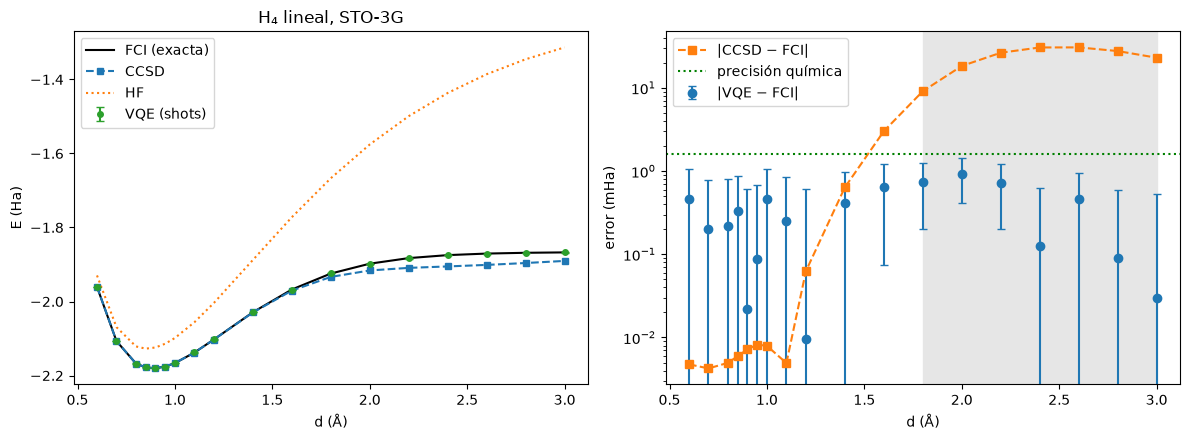

In [13]:
from h4vqe.analysis import plot_curve
fig = plot_curve(df, "curva_h4.png")

In [14]:
from h4vqe.analysis import fit_minimum, dissociation_energy, fit_minimum as _fm
fit = fit_minimum(df.d, df.E_vqe, df.sigma)
far = df[df.d == df.d.max()].iloc[0]
de = dissociation_energy(far.E_vqe, far.sigma, fit)
fit_fci = _fm(df.d, df.E_fci, np.full(len(df), 1e-6))
print(f"R_e (VQE) = {fit['R_e']:.4f} ± {fit['R_e_sigma']:.4f} Å   | R_e (FCI, mismo ajuste) = {fit_fci['R_e']:.4f} Å")
print(f"D_e (VQE) = {1e3*de['D_e']:.2f} ± {1e3*de['D_e_sigma']:.2f} mHa | D_e (FCI) = {1e3*(far.E_fci - fit_fci['E_min']):.2f} mHa")
s = df[df.d >= config.STRETCHED_FROM]
print(f"zona estirada: le gana a CCSD en {int(s.beats_ccsd.sum())}/{len(s)} puntos; precisión química en {int(s.chem_acc.sum())}/{len(s)}")

R_e (VQE) = 0.8969 ± 0.0014 Å   | R_e (FCI, mismo ajuste) = 0.8964 Å
D_e (VQE) = 312.94 ± 0.64 mHa | D_e (FCI) = 313.09 mHa
zona estirada: le gana a CCSD en 7/7 puntos; precisión química en 7/7


## 5 · ¿Por qué confiar en la zona estirada?  *(Joaquín)*

Argumentos que **no usan FCI**:
1. **Principio variacional:** E_VQE ≥ E₀ siempre (salvo ruido estadístico). CCSD no es variacional y queda *por debajo* de la exacta ⇒ entre los dos, el más bajo no es necesariamente el mejor; entre métodos variacionales, sí.
2. **Varianza de la energía** ⟨H²⟩ − ⟨H⟩² → 0 en un autoestado.
3. **Convergencia con la profundidad:** UCCSD ×1 → ×2 deja de cambiar.
4. **Simetrías:** ⟨N_α⟩ = ⟨N_β⟩ = 2 y ⟨S²⟩ = 0 (singlete).
5. **Calibración de σ:** las barras de error cubren lo que dicen cubrir.


In [15]:
from h4vqe.analysis import variance
from h4vqe.hamiltonian import number_operators
from h4vqe.optimize import optimize_params
diag = []
for d, c in ctxs.items():
    if d < config.STRETCHED_FROM: continue
    Hm = c["H"].to_matrix(sparse=True); psi = c["ansatz"].fast.state(c["opt"]["x"])
    ops = number_operators(c["m"]["norb"]); sv = Statevector(psi)
    a1 = build_ansatz(c["m"], reps=1); o1 = optimize_params(a1, c["H"], n_restarts=2)
    diag.append({"d": d, "var_H": variance(psi, Hm), "N_alpha": sv.expectation_value(ops["N_alpha"]).real,
                 "N_beta": sv.expectation_value(ops["N_beta"]).real, "S2": sv.expectation_value(ops["S2"]).real,
                 "E(reps=1) - E(reps=2) [mHa]": 1e3*(o1["energy"] - c["opt"]["energy"])})
pd.DataFrame(diag)

,d,var_H,N_alpha,N_beta,S2,E(reps=1) - E(reps=2) [mHa]
0,1.800000,0.000000,2.000000,2.000000,0.000000,3.274112
1,2.000000,0.000000,2.000000,2.000000,0.000000,4.462612
2,2.200000,0.000000,2.000000,2.000000,0.000000,3.079857
3,2.400000,0.000000,2.000000,2.000000,0.000000,1.768899
4,2.600000,0.000000,2.000000,2.000000,0.000002,1.003302
5,2.800000,0.000000,2.000000,2.000000,0.000003,0.565302
6,3.000000,0.000000,2.000000,2.000000,0.000024,0.314690


## 6 · Qué decidimos, qué no funcionó y limitaciones

| decisión | por qué | alternativa descartada |
|---|---|---|
| UCCSD ×2 | exacto en toda la curva | hardware-efficient: difícil de optimizar, rompe N |
| optimizar sin ruido | permitido; mucho más rápido | SPSA con shots: lento y ruidoso |
| SamplerV2 + σ propia | barras honestas, permite Neyman | EstimatorV2 con `precision`: σ fija |

**Qué no funcionó:** semillas consecutivas en el Sampler ⇒ σ subestimada (corregido).

**Limitaciones**
- **Compuertas:** UCCSD ×2 usa 582 CZ con conectividad total y 1648 con qubits en línea (columnas `cz_all` y `cz_line` de la tabla). Sin ruido no importa, pero con el 0,1 % de error por CZ del modelo de la consigna, la probabilidad de que no falle ninguna CZ sería 0,999^582 ≈ 56 % (todos con todos) y 0,999^1648 ≈ 19 % (en línea). En hardware actual este circuito no serviría sin bajar las CZ o mitigar.
- **Optimización sin ruido:** los parámetros se buscan con el simulador exacto, como permite la consigna. La curva mide qué tan expresivo es el ansatz más el ruido de los shots, no la dificultad de optimizar con mediciones.
- **σ es solo estadística:** cubre la dispersión de los shots (calibrada en la sección 3), no sesgos de ruido de compuertas o de lectura, que en esta simulación no hay.
- **Diagnósticos de la sección 5:** la varianza, las simetrías y la comparación con 1 paso de Trotter se calculan con el estado del simulador. En hardware habría que medirlos con shots.
- **Costo en shots:** 8 M por punto (144 M en las 18 distancias) para σ ≈ 0,5–0,6 mHa.
